# Infrastructure Optimization Engine
## Multi-Objective Optimization Analysis

**Student Name:** Pongsupa Supapa \
**Target Company/Industry:** Cloudflare, Inc. Cloud infrastructure and edge computing \
**Problem:** Find a workload placement and capacity configuration that balances infrastructure cost and response time. \
**Objectives:** Minimize estimated monthly infrastructure cost (USD) vs. minimize predicted demand-weighted response time (ms).

## Project Overview

This project aims to optimize the placement of application workloads across different geographic locations while minimizing infrastructure costs and application response times. This tradeoff is important to Cloudflare because increasing computing capacity and placing applications closer to users can improve performance but also increase operating costs. The decision variables I will control are the geographic placement of workloads and the amount of computing capacity allocated to each location. Unlike other optimization problems where higher objective values are preferred, this project focuses on minimizing both objectives to find the most efficient balance between cost and performance.

## Section 1: Data Acquisition

I use the processed data from my download data notebook, so `download_data.ipynb` needs to be run first. The data is downloaded and prepared separately so that this notebook can focus on the optimization and analysis. The datasets and their relevant variables are documented in `data/DATA_SOURCE.md`.

In [1]:
from pathlib import Path
from itertools import combinations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


data_folder = Path("data")
image_folder = Path("images")
image_folder.mkdir(exist_ok=True)

# Load the files prepared by the download notebook.
files = {
    "Alibaba workloads": "alibaba_joined.csv",
    "RIPE ping measurements": "original_ripe_ping_sample.csv",
    "RIPE regional latency": "ripe_region_rtt.csv",
    "Cloudflare pricing": "original_cloudflare_pricing.csv",
    "Cloudflare instances": "original_cloudflare_instances.csv"
}

for filename in files.values():
    if not (data_folder / filename).is_file():
        raise FileNotFoundError(f"Missing {filename}. Run the download data notebook first.")

joined = pd.read_csv(data_folder / files["Alibaba workloads"])
network = pd.read_csv(data_folder / files["RIPE ping measurements"])
network_summary = pd.read_csv(data_folder / files["RIPE regional latency"])
pricing = pd.read_csv(data_folder / files["Cloudflare pricing"])
instances = pd.read_csv(data_folder / files["Cloudflare instances"])

print("Data loaded successfully!")

for name, table in [("Alibaba workloads", joined), ("RIPE ping measurements", network),
                    ("RIPE regional latency", network_summary), ("Cloudflare pricing", pricing),
                    ("Cloudflare instances", instances)]:
    print(f"\n{name}: {table.shape}")
    display(table.head())

Data loaded successfully!

Alibaba workloads: (11959, 8)


,timestamp,msname,msinstanceid,nodeid,providerrpc_rt,providerrpc_mcr,cpu_utilization,memory_utilization
0,0,MS_10025,MS_10025_POD_52,NODE_29161,124.514563,3.034569e-06,0.120409,0.657554
1,0,MS_10025,MS_10025_POD_77,NODE_27651,145.019802,2.975646e-06,0.148975,0.674028
2,0,MS_10026,MS_10026_POD_11,NODE_26482,3.772036,6.461963e-06,0.037432,0.436981
3,0,MS_10042,MS_10042_POD_9,NODE_22628,584.800000,4.910306e-08,0.029340,0.483108
4,0,MS_10077,MS_10077_POD_17,NODE_40145,3.257154,1.211373e-04,0.198450,0.634625



RIPE ping measurements: (95974, 7)


,source_region,target_region,probe_id,target_anchor_id,measurement_id,timestamp,rtt_ms
0,Tokyo,US East,6370,1818,22252930,1794547059,154.250422
1,Tokyo,US East,6370,1818,22252930,1794547059,153.841995
2,Tokyo,US East,6370,1818,22252930,1794547059,155.003348
3,US West,US East,6411,1818,22252930,1794547055,72.849959
4,US West,US East,6411,1818,22252930,1794547055,70.912308



RIPE regional latency: (25, 4)


,source_region,target_region,latency_ms,packet_count
0,London,London,1.854787,2805
1,London,Singapore,164.665832,2798
2,London,Tokyo,230.014783,3881
3,London,US East,70.848953,3853
4,London,US West,141.366336,2786



Cloudflare pricing: (3, 5)


,parameter,rate,unit,source,accessed
0,cpu_vcpu_second,2.000000e-05,USD/vCPU-second,https://developers.cloudflare.com/containers/p...,2026-11-14
1,memory_gib_second,2.500000e-06,USD/GiB-second,https://developers.cloudflare.com/containers/p...,2026-11-14
2,disk_gb_second,7.000000e-08,USD/GB-second,https://developers.cloudflare.com/containers/p...,2026-11-14



Cloudflare instances: (6, 6)


,instance_type,vcpu,memory_gib,disk_gb,source,accessed
0,lite,0.0625,0.25,2.0,https://developers.cloudflare.com/containers/p...,2026-11-14
1,basic,0.2500,1.00,4.0,https://developers.cloudflare.com/containers/p...,2026-11-14
2,standard-1,0.5000,4.00,8.0,https://developers.cloudflare.com/containers/p...,2026-11-14
3,standard-2,1.0000,6.00,12.0,https://developers.cloudflare.com/containers/p...,2026-11-14
4,standard-3,2.0000,8.00,16.0,https://developers.cloudflare.com/containers/p...,2026-11-14


### Check the Processed Data

Before building the deployment configurations, I check that every region has a latency value, there are enough services, and the pricing data has all the rates and container sizes I need.

In [2]:
# Check the processed data before creating deployment configurations.
regions = ["US East", "US West", "London", "Singapore", "Tokyo"]

latency_matrix = network_summary.pivot(
    index="source_region", columns="target_region", values="latency_ms"
)
latency_matrix = latency_matrix.reindex(index=regions, columns=regions)

if latency_matrix.isna().any().any():
    raise ValueError("The processed RIPE data is missing one or more regional routes.")

if joined["msname"].nunique() < 6:
    raise ValueError("At least six distinct services are needed for the model.")

assert pricing["parameter"].is_unique and (pricing["rate"] > 0).all()
assert instances["instance_type"].is_unique

print("Regional latency matrix (ms):")
display(latency_matrix.round(2))

required_columns = {
    "Alibaba workloads": (joined, ["msname", "msinstanceid", "cpu_utilization", "memory_utilization", "providerrpc_rt", "providerrpc_mcr"]),
    "Cloudflare pricing": (pricing, ["parameter", "rate"]),
    "Cloudflare instances": (instances, ["instance_type", "vcpu", "memory_gib", "disk_gb"])
}

for name, (table, columns) in required_columns.items():
    if table.empty or not set(columns).issubset(table.columns):
        raise ValueError(f"Missing required data in {name}.")
    if table[columns].isna().any().any():
        raise ValueError(f"Missing values in {name}.")

if not np.isfinite(latency_matrix.to_numpy()).all() or (latency_matrix <= 0).any().any():
    raise ValueError("RIPE latency values must be finite and positive.")

required_rates = {"cpu_vcpu_second", "memory_gib_second", "disk_gb_second"}
required_sizes = {"basic", "standard-1", "standard-2", "standard-3", "standard-4"}

if not required_rates.issubset(pricing["parameter"]) or not required_sizes.issubset(instances["instance_type"]):
    raise ValueError("The Cloudflare pricing or instance data is incomplete.")

Regional latency matrix (ms):


target_region,US East,US West,London,Singapore,Tokyo
source_region,,,,,
US East,2.38,71.06,69.02,214.80,166.70
US West,68.07,11.97,136.75,173.40,114.47
London,70.85,141.37,1.85,164.67,230.01
Singapore,223.30,172.34,157.58,1.05,76.38
Tokyo,157.32,107.89,232.84,69.99,1.93


### Create Deployment Configurations

I select six distinct services with the most matching measurements and use one observed container per service. Since Alibaba normalizes its resource measurements, I use the published basic container size as a reference to convert each utilization value into estimated CPU and RAM demand. This is an assumption, not a recovery of Alibaba's physical capacity.

I compare all nonempty combinations of five regions and four published capacity tiers. The selected workloads are replicated in each active region, with each client region assigned to its lowest-RTT location. I split demand equally across client regions because the trace has no user geography, and weight the service response times by their normalized call rates as a relative demand proxy. The response-time estimate adds measured geographic RTT to the Alibaba RPC baseline; the original RPC time may already include network delay, so this is only an approximation.

I use peak CPU and memory requirements to check capacity, and mean CPU demand to estimate usage charges. Cost assumes 30 days of continuous activity, provisioned memory and disk, and active CPU usage, before allowances and other charges.

In [3]:
# Build workload profiles from real matched records.
selected_services = joined.groupby("msname").size().sort_values(ascending=False).head(6).index
sample = joined[joined["msname"].isin(selected_services)].copy()

# Use one representative container per service (most matched timestamps).
container_counts = sample.groupby(["msname", "msinstanceid"]).size().reset_index(name="count")
representatives = container_counts.sort_values("count", ascending=False).drop_duplicates("msname")
sample = sample.merge(representatives[["msname", "msinstanceid"]], on=["msname", "msinstanceid"])

sizes = instances.set_index("instance_type")
reference = sizes.loc["basic"]
workload_rows = []

for service, records in sample.groupby("msname"):
    weight = records["providerrpc_mcr"]
    workload_rows.append({
        "service": service,
        "observations": len(records),
        "relative_demand": weight.mean(),
        "rpc_ms": np.average(records["providerrpc_rt"], weights=weight),
        "mean_cpu": records["cpu_utilization"].mean() * reference["vcpu"],
        "peak_cpu": records["cpu_utilization"].max() * reference["vcpu"],
        "peak_memory_gib": records["memory_utilization"].max() * reference["memory_gib"]
    })

workloads = pd.DataFrame(workload_rows)
workloads.to_csv(data_folder / "workload_profiles.csv", index=False)
display(workloads)

base_latency = np.average(workloads["rpc_ms"], weights=workloads["relative_demand"])
mean_cpu = workloads["mean_cpu"].sum()
peak_cpu = workloads["peak_cpu"].sum()
peak_memory = workloads["peak_memory_gib"].sum()

selected_sizes = ["standard-1", "standard-2", "standard-3", "standard-4"]
instance_types = sizes.loc[selected_sizes]
rates = pricing.set_index("parameter")["rate"]
locations = list(regions)
seconds_per_month = 30 * 24 * 60 * 60

# Planning constraints (adjust if needed, not observed company limits).
budget_limit = 5000
latency_limit = 500
rows = []

for region_count in range(1, len(locations) + 1):
    for active_regions in combinations(locations, region_count):
        nearest = latency_matrix[list(active_regions)].idxmin(axis=1)
        network_latency = latency_matrix[list(active_regions)].min(axis=1).mean()
        shares = nearest.value_counts().reindex(active_regions, fill_value=0) / len(locations)

        for tier, size in enumerate(selected_sizes, start=1):
            instance = instance_types.loc[size]
            cpu = instance["vcpu"]
            memory = instance["memory_gib"]
            disk = instance["disk_gb"]

            max_cpu_demand = peak_cpu * shares.max()
            cpu_ok = max_cpu_demand <= cpu
            memory_ok = peak_memory <= memory

            # CPU is charged for active usage; memory and disk are provisioned.
            monthly_cost = seconds_per_month * (
                mean_cpu * rates["cpu_vcpu_second"]
                + region_count * (memory * rates["memory_gib_second"] + disk * rates["disk_gb_second"])
            )
            predicted_latency = base_latency + network_latency
            eligible = set(active_regions).issubset(locations)
            within_budget = monthly_cost <= budget_limit
            within_latency = predicted_latency <= latency_limit
            feasible = eligible and cpu_ok and memory_ok and within_budget and within_latency

            rows.append({
                "active_regions": ", ".join(active_regions),
                "region_count": region_count,
                "tier_index": tier,
                "instance_type": size,
                "vcpu_per_region": cpu,
                "memory_gib_per_region": memory,
                "peak_cpu_demand": max_cpu_demand,
                "peak_memory_demand_gib": peak_memory,
                "routing": "; ".join(f"{source}: {target}" for source, target in nearest.items()),
                "cost_usd_month": monthly_cost,
                "latency_ms": predicted_latency,
                "cpu_ok": cpu_ok,
                "memory_ok": memory_ok,
                "budget_ok": within_budget,
                "latency_ok": within_latency,
                "eligible": eligible,
                "feasible": feasible
            })

all_df = pd.DataFrame(rows)
all_df.to_csv(data_folder / "all_scenarios.csv", index=False)

# Only feasible plans can be on the frontier.
feasible_df = all_df[all_df["feasible"]].copy()
feasible_df.to_csv(data_folder / "feasible_scenarios.csv", index=False)
df = pd.read_csv(data_folder / "feasible_scenarios.csv")

assert len(all_df) == 124
if df.empty:
    display(all_df[["cpu_ok", "memory_ok", "budget_ok", "latency_ok", "eligible"]].sum())
    raise RuntimeError("No feasible plans. Review the workload profiles and planning limits.")

print("Deployment configurations created!")
print("Shape:", df.shape)
print("Total configurations:", len(all_df))
print("Feasible configurations:", len(df))
print("Excluded configurations:", len(all_df) - len(df))
display(df.head())

,service,observations,relative_demand,rpc_ms,mean_cpu,peak_cpu,peak_memory_gib
0,MS_10489,2,0.000010,18.044185,0.023911,0.025333,0.781114
1,MS_19988,1,0.000004,25.286396,0.029418,0.029418,0.629443
2,MS_29860,1,0.000043,15.055216,0.088853,0.088853,0.694230
3,MS_43157,2,0.000045,3.173659,0.089044,0.091485,0.663337
4,MS_48534,2,0.000004,27.796273,0.028748,0.029160,0.644674
5,MS_491,1,0.000010,18.139073,0.039609,0.039609,0.790181


Deployment configurations created!
Shape: (93, 17)
Total configurations: 124
Feasible configurations: 93
Excluded configurations: 31


,active_regions,region_count,tier_index,instance_type,vcpu_per_region,memory_gib_per_region,peak_cpu_demand,peak_memory_demand_gib,routing,cost_usd_month,latency_ms,cpu_ok,memory_ok,budget_ok,latency_ok,eligible,feasible
0,US East,1,2,standard-2,1.0,6.0,0.303858,4.202978,US East: US East; US West: US East; London: US...,56.587625,116.145075,True,True,True,True,True,True
1,US East,1,3,standard-3,2.0,8.0,0.303858,4.202978,US East: US East; US West: US East; London: US...,70.273385,116.145075,True,True,True,True,True,True
2,US East,1,4,standard-4,4.0,12.0,0.303858,4.202978,US East: US East; US West: US East; London: US...,96.919145,116.145075,True,True,True,True,True,True
3,US West,1,2,standard-2,1.0,6.0,0.303858,4.202978,US East: US West; US West: US West; London: US...,56.587625,112.685585,True,True,True,True,True,True
4,US West,1,3,standard-3,2.0,8.0,0.303858,4.202978,US East: US West; US West: US West; London: US...,70.273385,112.685585,True,True,True,True,True,True


## Section 2: Data Exploration

In [4]:
# Check the data quality first.
for name, data in [("Alibaba joined", joined), ("Workload profiles", workloads),
                   ("RIPE ping", network), ("Pricing", pricing),
                   ("Instance types", instances), ("Scenarios", df)]:
    print(f"\n{name}")
    print("Missing values:", data.isna().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())

print("\nScenario data types:")
print(df.dtypes)

print("\nBasic statistics:")
display(df[["tier_index", "region_count", "cost_usd_month", "latency_ms"]].describe().round(2))

# Decision variables: container tier and number of active regions.
print(f"Container tier range: {df['tier_index'].min()} to {df['tier_index'].max()}")
print("Tier order:", ", ".join(selected_sizes))
print(f"Active region range: {df['region_count'].min()} to {df['region_count'].max()}")
print(f"\nTotal combinations: {len(all_df)} ({len(df)} feasible)")

# Objectives: both are minimized.
print(f"\nCost range: ${df['cost_usd_month'].min():.2f} to ${df['cost_usd_month'].max():.2f}")
print(f"Latency range: {df['latency_ms'].min():.2f} to {df['latency_ms'].max():.2f} ms")

correlation = df["cost_usd_month"].corr(df["latency_ms"])
print(f"\nCorrelation between objectives: {correlation:.3f}")
print("(Negative correlation suggests a tradeoff)")


Alibaba joined
Missing values: 0
Duplicate rows: 0

Workload profiles
Missing values: 0
Duplicate rows: 0

RIPE ping
Missing values: 0
Duplicate rows: 1

Pricing
Missing values: 0
Duplicate rows: 0

Instance types
Missing values: 0
Duplicate rows: 0

Scenarios
Missing values: 0
Duplicate rows: 0

Scenario data types:
active_regions                str
region_count                int64
tier_index                  int64
instance_type                 str
vcpu_per_region           float64
memory_gib_per_region     float64
peak_cpu_demand           float64
peak_memory_demand_gib    float64
routing                       str
cost_usd_month            float64
latency_ms                float64
cpu_ok                       bool
memory_ok                    bool
budget_ok                    bool
latency_ok                   bool
eligible                     bool
feasible                     bool
dtype: object

Basic statistics:


,tier_index,region_count,cost_usd_month,latency_ms
count,93.00,93.00,93.00,93.00
mean,3.00,2.58,167.95,64.54
std,0.82,1.05,77.53,33.44
min,2.00,1.00,56.59,15.60
25%,2.00,2.00,97.64,40.61
50%,3.00,3.00,178.31,55.68
75%,4.00,3.00,179.76,84.85
max,4.00,5.00,422.47,136.54


Container tier range: 2 to 4
Tier order: standard-1, standard-2, standard-3, standard-4
Active region range: 1 to 5

Total combinations: 124 (93 feasible)

Cost range: $56.59 to $422.47
Latency range: 15.60 to 136.54 ms

Correlation between objectives: -0.728
(Negative correlation suggests a tradeoff)


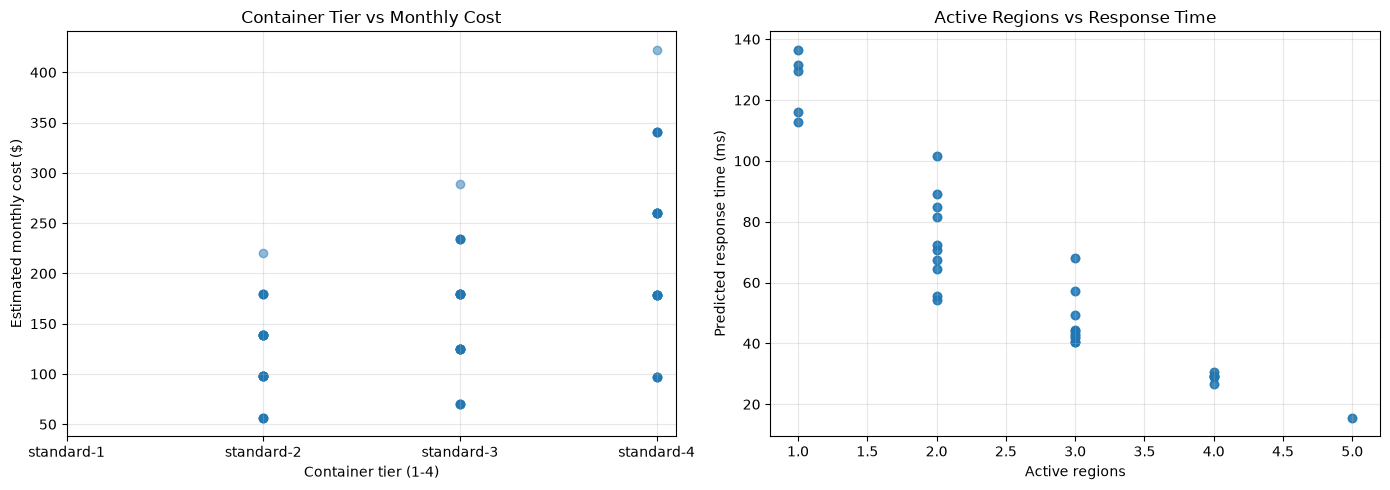

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: How container tier affects cost
axes[0].scatter(df["tier_index"], df["cost_usd_month"], alpha=0.5)
axes[0].set_xlabel("Container tier (1-4)")
axes[0].set_ylabel("Estimated monthly cost ($)")
axes[0].set_title("Container Tier vs Monthly Cost")
axes[0].set_xticks(range(1, len(selected_sizes) + 1), selected_sizes)
axes[0].grid(True, alpha=0.3)

# Plot 2: How the number of active regions affects response time
axes[1].scatter(df["region_count"], df["latency_ms"], alpha=0.5)
axes[1].set_xlabel("Active regions")
axes[1].set_ylabel("Predicted response time (ms)")
axes[1].set_title("Active Regions vs Response Time")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(image_folder / "data_exploration.png", dpi=300, bbox_inches="tight")
plt.show()

### Data Exploration Notes

The ranges look realistic for six services running on Cloudflare's published container prices. The monthly cost goes from \$56.59 to \$422.47, and the predicted response time goes from 15.60 ms to 136.54 ms, which fits the RIPE latency between the five regions. The correlation between cost and response time is -0.728, so there is a clear tradeoff. Adding more regions lowers the response time but raises the cost, because memory and disk are paid for in every active region.

There are no missing values, and the only issue is one duplicate RIPE ping row, which does not change the median latency. All 31 standard-1 configurations were excluded because the container does not have enough memory for the peak demand, so only tiers 2 to 4 are left. This matches what I expected, except that the container tier only changes the cost in this model and does not change the response time.

## Section 3: Pareto Frontier Calculation

Since I am minimizing both objectives, a point is dominated if another point has a lower or equal cost and latency, and is strictly lower in at least one of the two. The assignment uses `>=` and `>` for maximization, so I use `<=` and `<` instead.

In [6]:
def is_pareto_optimal(idx, df, obj1_col, obj2_col):
    """
    Check if a given row represents a Pareto optimal solution.

    A point is Pareto optimal if no other point dominates it.
    Both objectives are minimized, so point A dominates point B if A is
    lower or equal on both objectives and strictly lower on at least one.

    Parameters:
    -----------
    idx : int
        Index of the row to check
    df : DataFrame
        The full dataset
    obj1_col : str
        Column name for objective 1
    obj2_col : str
        Column name for objective 2

    Returns:
    --------
    bool : True if Pareto optimal, False if dominated
    """
    current_obj1 = df.loc[idx, obj1_col]
    current_obj2 = df.loc[idx, obj2_col]

    # Check if any other point dominates this one
    for other_idx in df.index:
        if other_idx == idx:
            continue

        other_obj1 = df.loc[other_idx, obj1_col]
        other_obj2 = df.loc[other_idx, obj2_col]

        # Flip the assignment's >= and > to <= and < for minimization.
        if (other_obj1 <= current_obj1 and
            other_obj2 <= current_obj2 and
            (other_obj1 < current_obj1 or other_obj2 < current_obj2)):
            return False  # This point is dominated

    return True  # No point dominates this one

In [7]:
# Both objectives need to be as LOW as possible.
OBJECTIVE_1 = "cost_usd_month"
OBJECTIVE_2 = "latency_ms"

print("Calculating Pareto frontier...")

# Apply Pareto check to all feasible rows
df["is_pareto_optimal"] = df.index.map(
    lambda idx: is_pareto_optimal(idx, df, OBJECTIVE_1, OBJECTIVE_2)
)

# Separate into frontier and dominated points
pareto_df = df[df["is_pareto_optimal"]].copy()
dominated_df = df[~df["is_pareto_optimal"]].copy()

print("\n=== PARETO FRONTIER RESULTS (LOWER IS BETTER) ===")
print(f"Total solutions analyzed: {len(df)}")
print(f"Pareto optimal solutions: {len(pareto_df)}")
print(f"Dominated solutions: {len(dominated_df)}")
print(f"Efficiency rate: {100 * len(pareto_df) / len(df):.1f}% of solutions are on the frontier")

# Verify that every plan is classified and every dominated plan has a better Pareto plan.
assert not pareto_df.empty
assert len(pareto_df) + len(dominated_df) == len(df)

for _, plan in dominated_df.iterrows():
    assert ((pareto_df[OBJECTIVE_1] <= plan[OBJECTIVE_1])
            & (pareto_df[OBJECTIVE_2] <= plan[OBJECTIVE_2])
            & ((pareto_df[OBJECTIVE_1] < plan[OBJECTIVE_1])
               | (pareto_df[OBJECTIVE_2] < plan[OBJECTIVE_2]))).any()

pareto_df.to_csv(data_folder / "pareto_frontier.csv", index=False)

print(f"\nCost range on frontier: ${pareto_df[OBJECTIVE_1].min():.2f} to ${pareto_df[OBJECTIVE_1].max():.2f}")
print(f"Latency range on frontier: {pareto_df[OBJECTIVE_2].min():.2f} to {pareto_df[OBJECTIVE_2].max():.2f} ms")
print("\nPareto optimal plans:")
display(pareto_df.sort_values(OBJECTIVE_1)[["active_regions", "instance_type", OBJECTIVE_1, OBJECTIVE_2]])

Calculating Pareto frontier...

=== PARETO FRONTIER RESULTS (LOWER IS BETTER) ===
Total solutions analyzed: 93
Pareto optimal solutions: 5
Dominated solutions: 88
Efficiency rate: 5.4% of solutions are on the frontier

Cost range on frontier: $56.59 to $220.82
Latency range on frontier: 15.60 to 112.69 ms

Pareto optimal plans:


,active_regions,instance_type,cost_usd_month,latency_ms
3,US West,standard-2,56.587625,112.685585
21,"US East, Singapore",standard-2,97.644905,54.226722
54,"US East, London, Singapore",standard-2,138.702185,40.427889
84,"US East, London, Singapore, Tokyo",standard-2,179.759465,26.814785
90,"US East, US West, London, Singapore, Tokyo",standard-2,220.816745,15.596047


### Pareto Frontier Notes

Only 5 of the 93 feasible plans (5.4%) are Pareto optimal, and the other 88 are dominated. This is what I expected after the data exploration, because the container tier only changes the cost and not the response time. Every standard-3 and standard-4 plan is dominated by the standard-2 plan with the same regions, which has the same latency for less money.

The frontier has one plan for each region count, from 1 region (US West, \$56.59, 112.69 ms) to all 5 regions (\$220.82, 15.60 ms). Each extra region adds about \$41 per month, while the latency savings get smaller with each region. This tells me the real tradeoff is how many regions to run in, and the cheapest container that fits the workload is always the right size.

### Inefficient Solutions Analysis

A better solution has a lower cost or a lower latency without increasing the other objective. I compare each dominated plan with a Pareto plan that actually dominates it, because not every Pareto plan is better than every dominated plan.

In [8]:
def find_dominating_plan(plan, frontier):
    """Return the cheapest Pareto plan that dominates the given plan (both objectives minimized)."""
    better_plans = frontier[
        (frontier[OBJECTIVE_1] <= plan[OBJECTIVE_1])
        & (frontier[OBJECTIVE_2] <= plan[OBJECTIVE_2])
        & ((frontier[OBJECTIVE_1] < plan[OBJECTIVE_1])
           | (frontier[OBJECTIVE_2] < plan[OBJECTIVE_2]))
    ]

    if better_plans.empty:
        raise AssertionError("A dominated plan must have a dominating Pareto plan.")

    return better_plans.sort_values([OBJECTIVE_1, OBJECTIVE_2]).iloc[0]


def describe(plan):
    return f"{plan['active_regions']} ({plan['instance_type']})"


efficiency_rows = []

if len(dominated_df) > 0:
    print("=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===\n")

    # Sample a few dominated points
    sample_size = min(3, len(dominated_df))
    sample_dominated = dominated_df.sample(sample_size, random_state=42)

    for idx, row in sample_dominated.iterrows():
        better = find_dominating_plan(row, pareto_df)
        cost_saved = row[OBJECTIVE_1] - better[OBJECTIVE_1]
        latency_saved = row[OBJECTIVE_2] - better[OBJECTIVE_2]

        print("INEFFICIENT SOLUTION:")
        print(f"  Decision Variables: {describe(row)}")
        print(f"  Objectives: cost=${row[OBJECTIVE_1]:.2f}, latency={row[OBJECTIVE_2]:.2f} ms")
        print("\n  BETTER ALTERNATIVE (Pareto Optimal):")
        print(f"  Decision Variables: {describe(better)}")
        print(f"  Objectives: cost=${better[OBJECTIVE_1]:.2f}, latency={better[OBJECTIVE_2]:.2f} ms")
        print(f"  Improvement: saves ${cost_saved:.2f} per month and {latency_saved:.2f} ms\n")
        print("-" * 60)

    # Apply the same check to every dominated plan, not only the sample.
    for idx, row in dominated_df.iterrows():
        better = find_dominating_plan(row, pareto_df)
        efficiency_rows.append({
            "dominated_plan": describe(row),
            "better_plan": describe(better),
            "cost_saved": row[OBJECTIVE_1] - better[OBJECTIVE_1],
            "latency_saved_ms": row[OBJECTIVE_2] - better[OBJECTIVE_2]
        })
else:
    print("Note: All solutions in your dataset are Pareto optimal.")
    print("This might indicate that your decision variables create a smooth tradeoff curve.")

improvements = pd.DataFrame(efficiency_rows)

=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===

INEFFICIENT SOLUTION:
  Decision Variables: US East, US West, London, Tokyo (standard-3)
  Objectives: cost=$234.50, latency=30.66 ms

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: US East, London, Singapore, Tokyo (standard-2)
  Objectives: cost=$179.76, latency=26.81 ms
  Improvement: saves $54.74 per month and 3.85 ms

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: US East (standard-2)
  Objectives: cost=$56.59, latency=116.15 ms

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: US West (standard-2)
  Objectives: cost=$56.59, latency=112.69 ms
  Improvement: saves $0.00 per month and 3.46 ms

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: US West, London (standard-3)
  Objectives: cost=$125.02, latency=81.42 ms

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: US East, Singapo

In [9]:
# Compare efficient and inefficient solutions.
groups = df.assign(group=np.where(df["is_pareto_optimal"], "Pareto optimal", "Dominated"))
summary_stats = groups.groupby("group").agg(
    plans=(OBJECTIVE_1, "size"),
    mean_cost=(OBJECTIVE_1, "mean"),
    min_cost=(OBJECTIVE_1, "min"),
    max_cost=(OBJECTIVE_1, "max"),
    mean_latency_ms=(OBJECTIVE_2, "mean"),
    min_latency_ms=(OBJECTIVE_2, "min"),
    max_latency_ms=(OBJECTIVE_2, "max"),
    mean_tier=("tier_index", "mean"),
    mean_regions=("region_count", "mean")
)

print("=== EFFICIENT VS. INEFFICIENT SOLUTIONS ===")
display(summary_stats.round(2))

print("Plans by container tier:")
display(pd.crosstab(groups["instance_type"], groups["group"]))

if not improvements.empty:
    print("Savings available by switching each dominated plan to a better Pareto plan:")
    display(improvements[["cost_saved", "latency_saved_ms"]].describe().round(2))

# Compare the best dominated plan with an actual better alternative.
# Cost and latency have different units, so normalize them before scoring.
if len(dominated_df) > 0:
    cost_range = df[OBJECTIVE_1].max() - df[OBJECTIVE_1].min()
    latency_range = df[OBJECTIVE_2].max() - df[OBJECTIVE_2].min()

    scores = (dominated_df[OBJECTIVE_1] - df[OBJECTIVE_1].min()) / (cost_range or 1)
    scores += (dominated_df[OBJECTIVE_2] - df[OBJECTIVE_2].min()) / (latency_range or 1)
    best_dominated = dominated_df.loc[scores.idxmin()]
    alternative = find_dominating_plan(best_dominated, pareto_df)

    print("\n=== EFFICIENCY GAP ===")
    print("Even the BEST dominated plan (normalized score) has a better Pareto alternative:")
    display(pd.DataFrame([best_dominated, alternative], index=["Best dominated", "Better alternative"])[
        ["active_regions", "instance_type", OBJECTIVE_1, OBJECTIVE_2]].round(2))

=== EFFICIENT VS. INEFFICIENT SOLUTIONS ===


,plans,mean_cost,min_cost,max_cost,mean_latency_ms,min_latency_ms,max_latency_ms,mean_tier,mean_regions
group,,,,,,,,,
Dominated,88,169.61,56.59,422.47,65.37,15.6,136.54,3.06,2.56
Pareto optimal,5,138.70,56.59,220.82,49.95,15.6,112.69,2.00,3.00


Plans by container tier:


group,Dominated,Pareto optimal
instance_type,,
standard-2,26,5
standard-3,31,0
standard-4,31,0


Savings available by switching each dominated plan to a better Pareto plan:


,cost_saved,latency_saved_ms
count,88.00,88.00
mean,51.91,10.69
std,51.97,12.10
min,0.00,0.00
25%,0.00,2.11
50%,40.69,3.85
75%,80.66,16.97
max,201.66,47.29



=== EFFICIENCY GAP ===
Even the BEST dominated plan (normalized score) has a better Pareto alternative:


,active_regions,instance_type,cost_usd_month,latency_ms
Best dominated,"US East, Singapore, Tokyo",standard-2,138.7,40.61
Better alternative,"US East, London, Singapore",standard-2,138.7,40.43


### Inefficient Solutions Notes

All 62 standard-3 and standard-4 plans are dominated, and so are 26 of the 31 standard-2 plans. The bigger containers cost more but do not make the response time any faster, so they are wasted money in this model. Switching each dominated plan to a better Pareto plan saves \$51.91 per month and 10.69 ms on average, and up to \$201.66 or 47.29 ms.

The standard-2 plans that are dominated have the same cost as a Pareto plan with the same number of regions, but they use the wrong regions. For example, running only in US East is 3.46 ms slower than running only in US West for the same price. Even the best dominated plan (US East, Singapore and Tokyo) loses to US East, London and Singapore, which costs the same and is slightly faster. This shows that both the container size and the choice of regions matter, and picking the wrong one of either gives an inefficient plan.

## Section 4: Strategic Analysis

Cost and latency have different units, so I normalize both objectives on the frontier before comparing them. A score of 0 is the best value on the frontier and 1 is the worst. Since lower is better, I use `idxmin()` to pick the plan for every strategy instead of the `idxmax()` in the assignment.

In [10]:
def normalize_low_is_better(values):
    """Scale values to 0 (best, lowest) to 1 (worst, highest)."""
    lowest = values.min()
    highest = values.max()

    if highest == lowest:
        return pd.Series(0.0, index=values.index)

    return (values - lowest) / (highest - lowest)


pareto_df["cost_score"] = normalize_low_is_better(pareto_df[OBJECTIVE_1])
pareto_df["latency_score"] = normalize_low_is_better(pareto_df[OBJECTIVE_2])

# Strategy 1: Balanced (lowest combined normalized score)
pareto_df["balanced_score"] = 0.5 * pareto_df["cost_score"] + 0.5 * pareto_df["latency_score"]
balanced_idx = pareto_df["balanced_score"].idxmin()

# Strategy 2: Equity (smallest gap between the two normalized scores)
pareto_df["objective_gap"] = abs(pareto_df["cost_score"] - pareto_df["latency_score"])
equity_idx = pareto_df["objective_gap"].idxmin()

# Strategy 3: Objective 1 priority (lowest cost)
obj1_priority_idx = pareto_df[OBJECTIVE_1].idxmin()

# Strategy 4: Objective 2 priority (lowest latency)
obj2_priority_idx = pareto_df[OBJECTIVE_2].idxmin()

# Strategy 5: Weighted (60% cost, 40% latency)
pareto_df["weighted_score"] = 0.6 * pareto_df["cost_score"] + 0.4 * pareto_df["latency_score"]
weighted_idx = pareto_df["weighted_score"].idxmin()

choices = {
    "1. BALANCED STRATEGY (Lowest combined normalized score)": (balanced_idx, "balanced_score", "Score"),
    "2. EQUITY STRATEGY (Most equal normalized scores)": (equity_idx, "objective_gap", "Gap"),
    "3. COST PRIORITY (Lowest monthly cost)": (obj1_priority_idx, None, None),
    "4. LATENCY PRIORITY (Lowest response time)": (obj2_priority_idx, None, None),
    "5. WEIGHTED STRATEGY (60% cost, 40% latency)": (weighted_idx, "weighted_score", "Score")
}

print("=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===\n")

for title, (idx, score_column, score_name) in choices.items():
    plan = pareto_df.loc[idx]
    print(title)
    print(f"   Decision Variables: tier={plan['instance_type']}, active regions={plan['region_count']} ({plan['active_regions']})")
    print(f"   Cost: ${plan[OBJECTIVE_1]:.2f} per month")
    print(f"   Latency: {plan[OBJECTIVE_2]:.2f} ms")
    if score_column:
        print(f"   {score_name}: {plan[score_column]:.3f}")
    print()

=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===

1. BALANCED STRATEGY (Lowest combined normalized score)
   Decision Variables: tier=standard-2, active regions=2 (US East, Singapore)
   Cost: $97.64 per month
   Latency: 54.23 ms
   Score: 0.324

2. EQUITY STRATEGY (Most equal normalized scores)
   Decision Variables: tier=standard-2, active regions=2 (US East, Singapore)
   Cost: $97.64 per month
   Latency: 54.23 ms
   Gap: 0.148

3. COST PRIORITY (Lowest monthly cost)
   Decision Variables: tier=standard-2, active regions=1 (US West)
   Cost: $56.59 per month
   Latency: 112.69 ms

4. LATENCY PRIORITY (Lowest response time)
   Decision Variables: tier=standard-2, active regions=5 (US East, US West, London, Singapore, Tokyo)
   Cost: $220.82 per month
   Latency: 15.60 ms

5. WEIGHTED STRATEGY (60% cost, 40% latency)
   Decision Variables: tier=standard-2, active regions=2 (US East, Singapore)
   Cost: $97.64 per month
   Latency: 54.23 ms
   Score: 0.309



In [11]:
# Build comparison dataframe, ordered from cost priority to latency priority.
order = [
    ("Cost Priority", obj1_priority_idx),
    ("Weighted (60/40)", weighted_idx),
    ("Balanced", balanced_idx),
    ("Equity", equity_idx),
    ("Latency Priority", obj2_priority_idx)
]

comparison_df = pd.DataFrame([{
    "Strategy": name,
    "Container Tier": pareto_df.loc[idx, "instance_type"],
    "Active Regions": int(pareto_df.loc[idx, "region_count"]),
    "Locations": pareto_df.loc[idx, "active_regions"],
    "Cost ($/month)": round(pareto_df.loc[idx, OBJECTIVE_1], 2),
    "Latency (ms)": round(pareto_df.loc[idx, OBJECTIVE_2], 2)
} for name, idx in order])

print("=" * 110)
print("STRATEGIC OPTIONS COMPARISON (LOWER COST AND LATENCY ARE BETTER)")
print("=" * 110)
print(comparison_df.to_string(index=False))
print("=" * 110)

comparison_df.to_csv(data_folder / "strategic_options.csv", index=False)

STRATEGIC OPTIONS COMPARISON (LOWER COST AND LATENCY ARE BETTER)
        Strategy Container Tier  Active Regions                                  Locations  Cost ($/month)  Latency (ms)
   Cost Priority     standard-2               1                                    US West           56.59        112.69
Weighted (60/40)     standard-2               2                         US East, Singapore           97.64         54.23
        Balanced     standard-2               2                         US East, Singapore           97.64         54.23
          Equity     standard-2               2                         US East, Singapore           97.64         54.23
Latency Priority     standard-2               5 US East, US West, London, Singapore, Tokyo          220.82         15.60


In [12]:
# Which plan does each cost weight pick? (latency weight = 1 - cost weight)
sensitivity_rows = []

for cost_weight in np.round(np.arange(0, 1.001, 0.05), 2):
    score = cost_weight * pareto_df["cost_score"] + (1 - cost_weight) * pareto_df["latency_score"]
    plan = pareto_df.loc[score.idxmin()]
    sensitivity_rows.append({
        "Cost Weight": cost_weight,
        "Latency Weight": round(1 - cost_weight, 2),
        "Active Regions": int(plan["region_count"]),
        "Locations": plan["active_regions"],
        "Cost ($/month)": round(plan[OBJECTIVE_1], 2),
        "Latency (ms)": round(plan[OBJECTIVE_2], 2)
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
print("WEIGHT SENSITIVITY: HOW THE PRIORITY CHANGES THE CHOSEN PLAN")
print(sensitivity_df.to_string(index=False))

WEIGHT SENSITIVITY: HOW THE PRIORITY CHANGES THE CHOSEN PLAN
 Cost Weight  Latency Weight  Active Regions                                  Locations  Cost ($/month)  Latency (ms)
        0.00            1.00               5 US East, US West, London, Singapore, Tokyo          220.82         15.60
        0.05            0.95               5 US East, US West, London, Singapore, Tokyo          220.82         15.60
        0.10            0.90               5 US East, US West, London, Singapore, Tokyo          220.82         15.60
        0.15            0.85               5 US East, US West, London, Singapore, Tokyo          220.82         15.60
        0.20            0.80               5 US East, US West, London, Singapore, Tokyo          220.82         15.60
        0.25            0.75               5 US East, US West, London, Singapore, Tokyo          220.82         15.60
        0.30            0.70               5 US East, US West, London, Singapore, Tokyo          220.82         1

### Strategic Analysis Notes

- **Cost Priority (US West, \$56.59, 112.69 ms):** This is the cheapest plan that still fits the workload. It makes sense for internal tools, batch jobs, or a new product where the budget matters more than speed. Users in Asia and Europe have to wait the longest.
- **Latency Priority (all 5 regions, \$220.82, 15.60 ms):** Every client region gets a local copy of the workload, so this is the plan for real-time or customer-facing apps. It costs almost 4 times the cheapest plan to cut the response time by about 97 ms.
- **Balanced, Equity and Weighted 60/40 (US East and Singapore, \$97.64, 54.23 ms):** All three strategies pick the same plan. Adding a second region gives the biggest drop in response time on the frontier (58 ms for \$41 more), so this plan wins for any cost weight from 0.40 to 0.70. It covers the Americas and Europe from US East and Asia from Singapore.

The weight sensitivity table shows how a change in priority moves the chosen plan along the frontier. Below a cost weight of 0.35 the company should run in all 5 regions, and above 0.70 it should run in only 1 region. The 3 and 4 region plans are only picked in a narrow range around 0.35, since each extra region after the second one saves less time for the same \$41 per month. For most companies, the decision comes down to 1, 2 or 5 regions, and the right answer depends on how much each millisecond is worth to their users.

## Section 5: Visualization